# 04 – Expression EDA
Checks library sizes, normalisation, batch effects (plate and hospital), PCA, UMAP and clustering.

## Setup
Loads the cleaned metadata and the log2-CPM matrix. The sequencing plate and tissue source site are taken from the TCGA barcode.

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.patches import Patch
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import umap

PROC = Path("../data/processed")
FIG  = Path("../results/figures"); TAB = Path("../results/tables")

meta   = pd.read_csv(PROC / "meta_clean.csv")
logcpm = pd.read_csv(PROC / "logcpm.csv", index_col="gene")          # genes x samples
counts = pd.read_csv(PROC / "counts_filtered.csv", index_col="gene_id")
assert (logcpm.columns == meta["sample_id"]).all()

SUB_ORDER = ["LumA", "LumB", "Her2", "Basal", "Normal"]
PALETTE   = dict(zip(SUB_ORDER, ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]))
sns.set_theme(style="whitegrid", font_scale=1.05)

# batch variables from the TCGA barcode
meta["plate"] = meta["aliquot"].str[21:25]     # sequencing plate, e.g. A12D
meta["tss"]   = meta["sample_id"].str[5:7]     # tissue source site (hospital)
print("Plates:", meta["plate"].nunique(), "| Tissue source sites:", meta["tss"].nunique())

Plates: 43 | Tissue source sites: 40


## Library size and the effect of normalisation
Raw read counts depend on sequencing depth, so samples aren't directly comparable.
Left: library size per subtype. Middle and right: 60 random samples before and after log2-CPM normalisation.

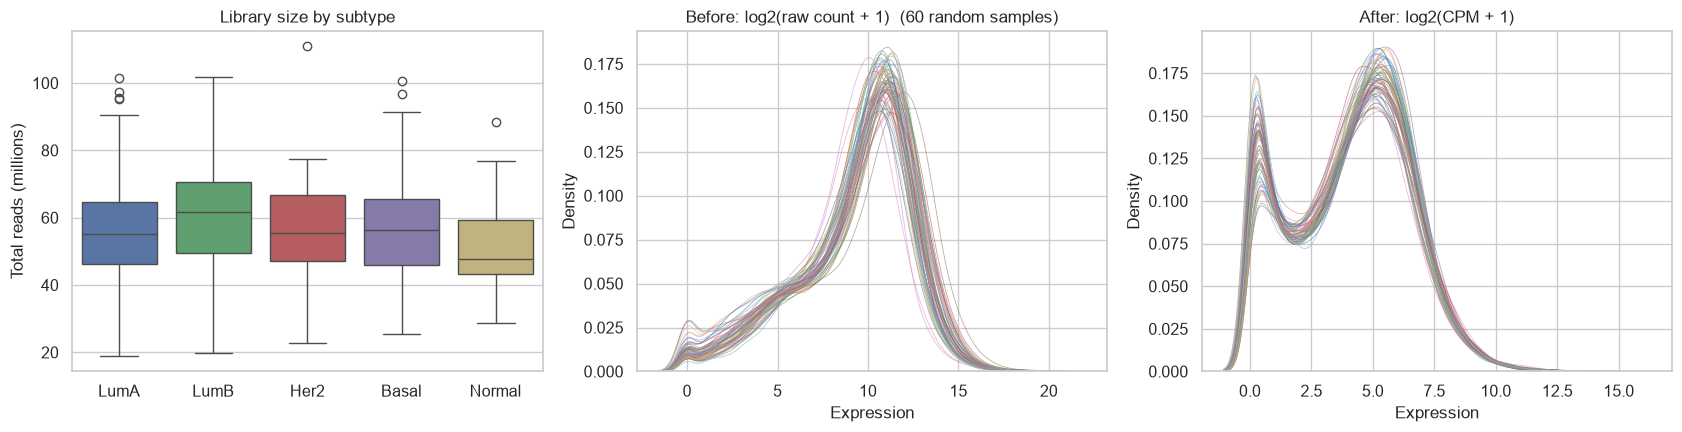

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=meta, x="subtype", y="library_size_M", order=SUB_ORDER, hue="subtype",
            palette=PALETTE, ax=axes[0], legend=False)
axes[0].set(title="Library size by subtype", xlabel="", ylabel="Total reads (millions)")

rng = np.random.default_rng(42)
idx = rng.choice(len(meta), 60, replace=False)
raw_log = np.log2(counts.iloc[:, idx] + 1)
for j in range(len(idx)):
    sns.kdeplot(raw_log.iloc[:, j], ax=axes[1], lw=0.6, alpha=0.6, legend=False)
    sns.kdeplot(logcpm.iloc[:, idx[j]], ax=axes[2], lw=0.6, alpha=0.6, legend=False)
axes[1].set(title="Before: log2(raw count + 1)  (60 random samples)", xlabel="Expression")
axes[2].set(title="After: log2(CPM + 1)", xlabel="Expression")
plt.tight_layout(); plt.savefig(FIG / "04_library_size_normalisation.png", dpi=200); plt.show()

# Gene variance distribution and highly variable genes (HVG)

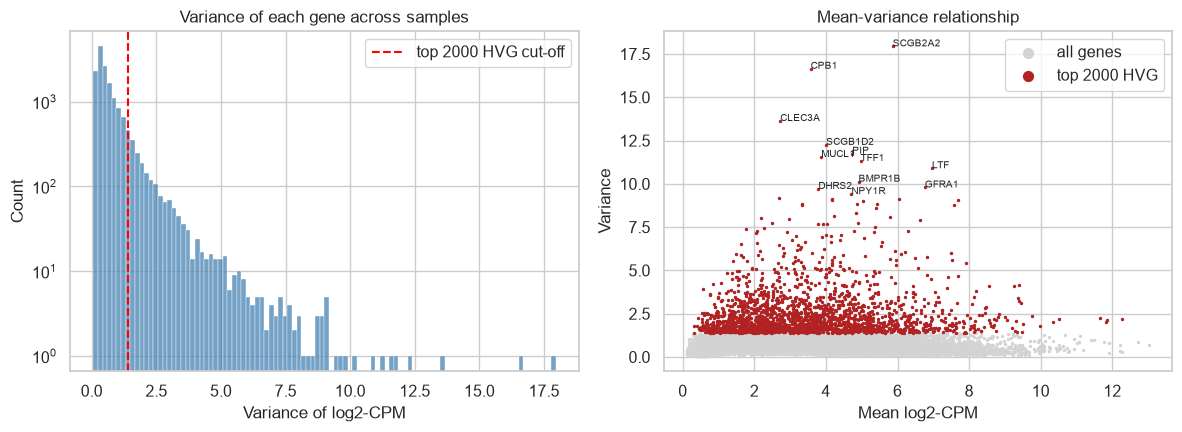

Top 20 most variable genes: ['SCGB2A2', 'CPB1', 'CLEC3A', 'SCGB1D2', 'PIP', 'MUCL1', 'TFF1', 'LTF', 'BMPR1B', 'GFRA1', 'DHRS2', 'NPY1R', 'KCNJ3', 'TFF3', 'TFAP2B', 'AGR2', 'GABRP', 'PGR', 'CYP4Z1', 'KRT5']


In [4]:
gene_mean = logcpm.mean(axis=1)
gene_var  = logcpm.var(axis=1)
N_HVG = 2000
hvg = gene_var.sort_values(ascending=False).index[:N_HVG]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(gene_var, bins=100, ax=axes[0], color="steelblue")
axes[0].axvline(gene_var[hvg].min(), color="red", ls="--", label=f"top {N_HVG} HVG cut-off")
axes[0].set(title="Variance of each gene across samples", xlabel="Variance of log2-CPM", yscale="log"); axes[0].legend()
axes[1].scatter(gene_mean, gene_var, s=2, c="lightgrey", label="all genes")
axes[1].scatter(gene_mean[hvg], gene_var[hvg], s=2, c="firebrick", label=f"top {N_HVG} HVG")
for g in gene_var.sort_values(ascending=False).index[:12]:
    axes[1].annotate(g, (gene_mean[g], gene_var[g]), fontsize=7)
axes[1].set(title="Mean-variance relationship", xlabel="Mean log2-CPM", ylabel="Variance"); axes[1].legend(markerscale=5)
plt.tight_layout(); plt.savefig(FIG / "04_gene_variance.png", dpi=200); plt.show()
print("Top 20 most variable genes:", list(gene_var.sort_values(ascending=False).index[:20]))

# marker genes by subtype (violin plots)

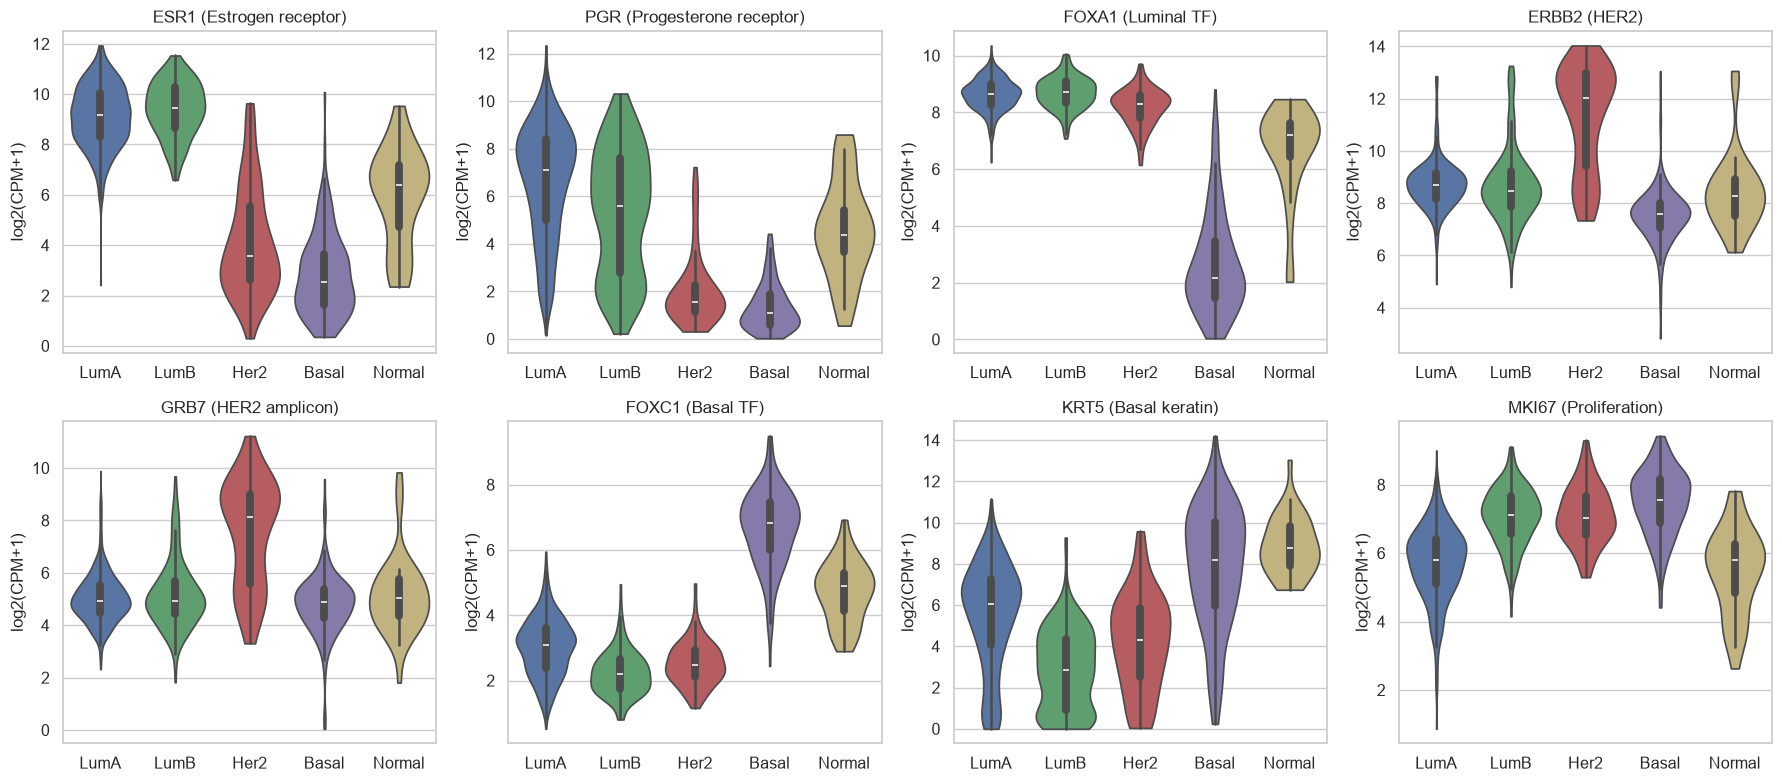

In [5]:
markers = {"ESR1": "Estrogen receptor", "PGR": "Progesterone receptor", "FOXA1": "Luminal TF",
           "ERBB2": "HER2", "GRB7": "HER2 amplicon", "FOXC1": "Basal TF",
           "KRT5": "Basal keratin", "MKI67": "Proliferation"}
long = (logcpm.loc[list(markers)].T.assign(subtype=meta["subtype"].values)
              .melt(id_vars="subtype", var_name="gene", value_name="log2CPM"))
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (g, desc) in zip(axes.flat, markers.items()):
    sns.violinplot(data=long[long.gene == g], x="subtype", y="log2CPM", order=SUB_ORDER, hue="subtype",
                   palette=PALETTE, cut=0, inner="box", ax=ax, legend=False)
    ax.set(title=f"{g} ({desc})", xlabel="", ylabel="log2(CPM+1)")
plt.tight_layout(); plt.savefig(FIG / "04_marker_genes_violin.png", dpi=200); plt.show()

# heatmap of the top 50 variable genes, with hierarchical clustering

c:\Users\srika\Downloads\TCGA_BRCA_project\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\Users\srika\Downloads\TCGA_BRCA_project\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


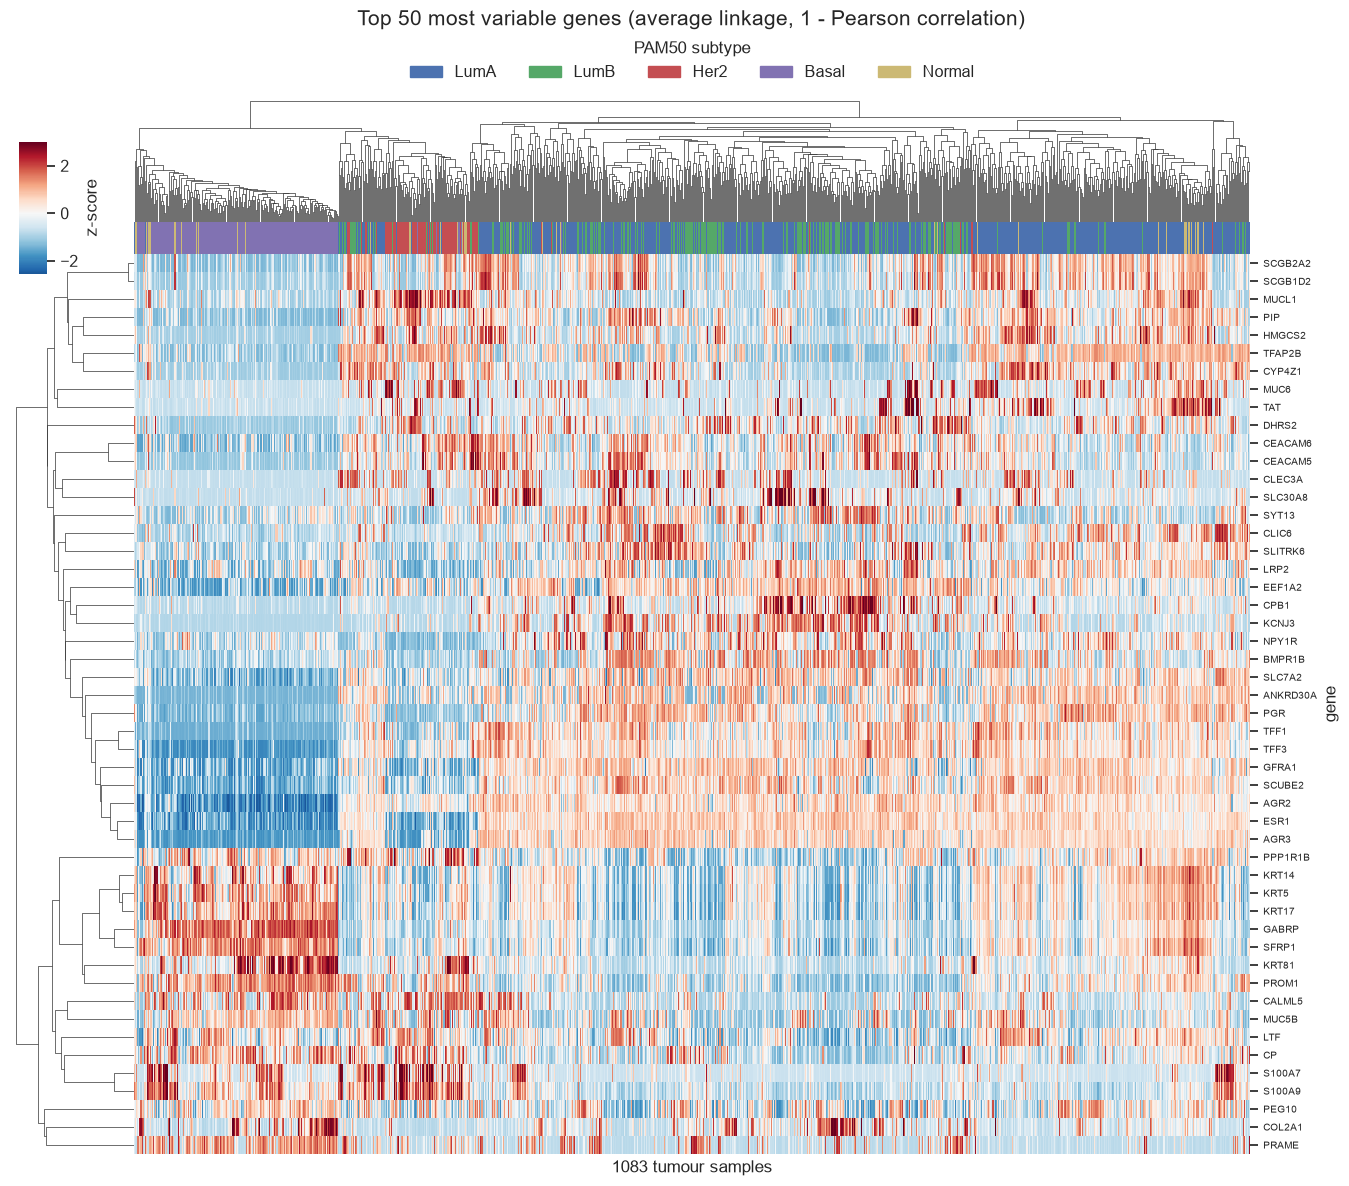

In [7]:
top50 = hvg[:50]
z = logcpm.loc[top50]
z = z.sub(z.mean(axis=1), axis=0).div(z.std(axis=1), axis=0).clip(-3, 3)   # z-score per gene
col_colors = meta["subtype"].map(PALETTE).values
cg = sns.clustermap(z, cmap="RdBu_r", center=0, col_colors=[col_colors], method="average",
                    metric="correlation", xticklabels=False, yticklabels=True, figsize=(14, 11),
                    cbar_pos=(0.02, 0.82, 0.02, 0.12), cbar_kws={"label": "z-score"},
                    dendrogram_ratio=(0.1, 0.12))
cg.ax_heatmap.set_xlabel(f"{z.shape[1]} tumour samples"); cg.ax_heatmap.tick_params(axis="y", labelsize=7)
cg.ax_col_dendrogram.legend(handles=[Patch(color=PALETTE[s], label=s) for s in SUB_ORDER],
                            ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, title="PAM50 subtype")
cg.figure.suptitle("Top 50 most variable genes (average linkage, 1 - Pearson correlation)", y=1.06)
cg.savefig(FIG / "04_heatmap_top50.png", dpi=200, bbox_inches="tight"); plt.show()

# correlation between key breast-cancer genes

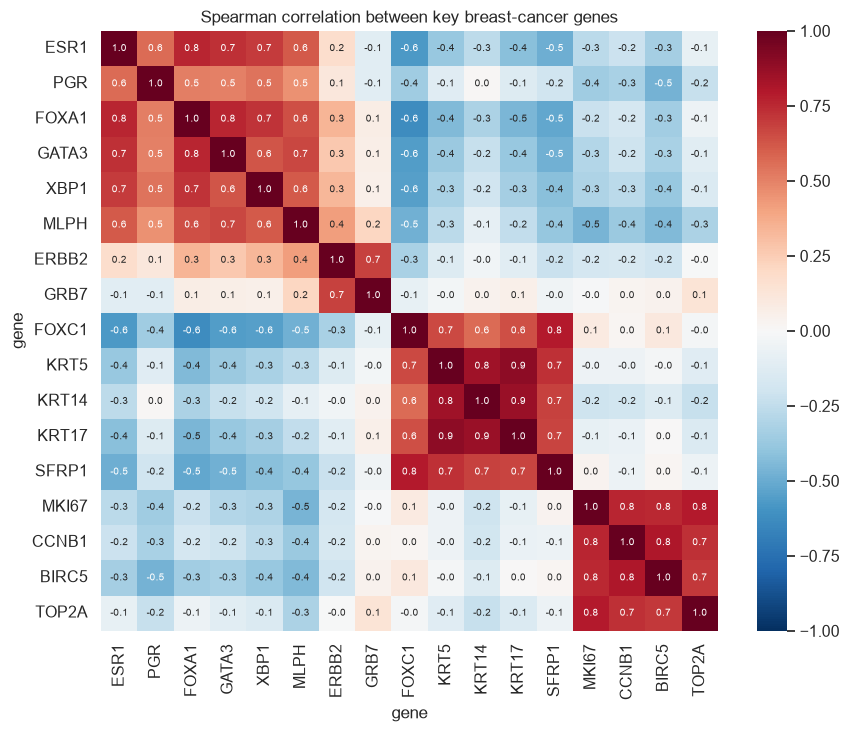

In [8]:
corr_genes = ["ESR1", "PGR", "FOXA1", "GATA3", "XBP1", "MLPH", "ERBB2", "GRB7",
              "FOXC1", "KRT5", "KRT14", "KRT17", "SFRP1", "MKI67", "CCNB1", "BIRC5", "TOP2A"]
corr = logcpm.loc[corr_genes].T.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation between key breast-cancer genes")
plt.tight_layout(); plt.savefig(FIG / "04_gene_correlation.png", dpi=200); plt.show()

# PCA on the top 2000 HVG

PC1 14.7%, PC2 8.9%, first 10 PCs 44.8%, first 50 PCs 64.8%


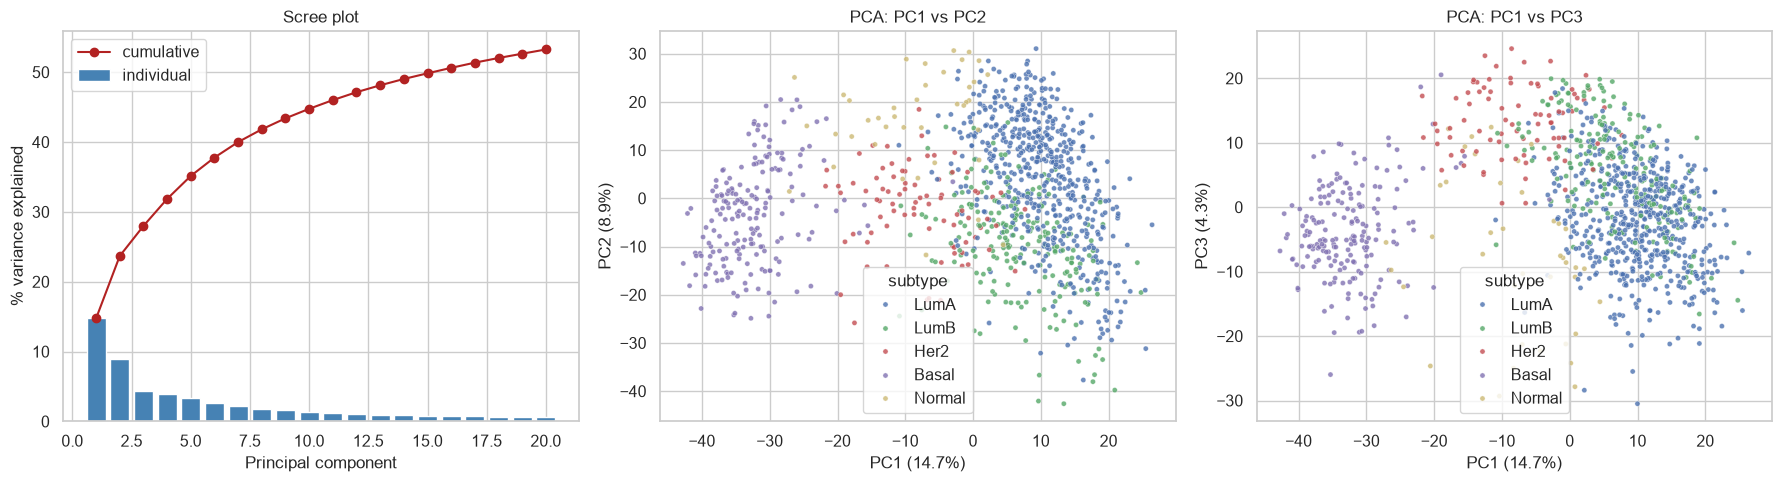

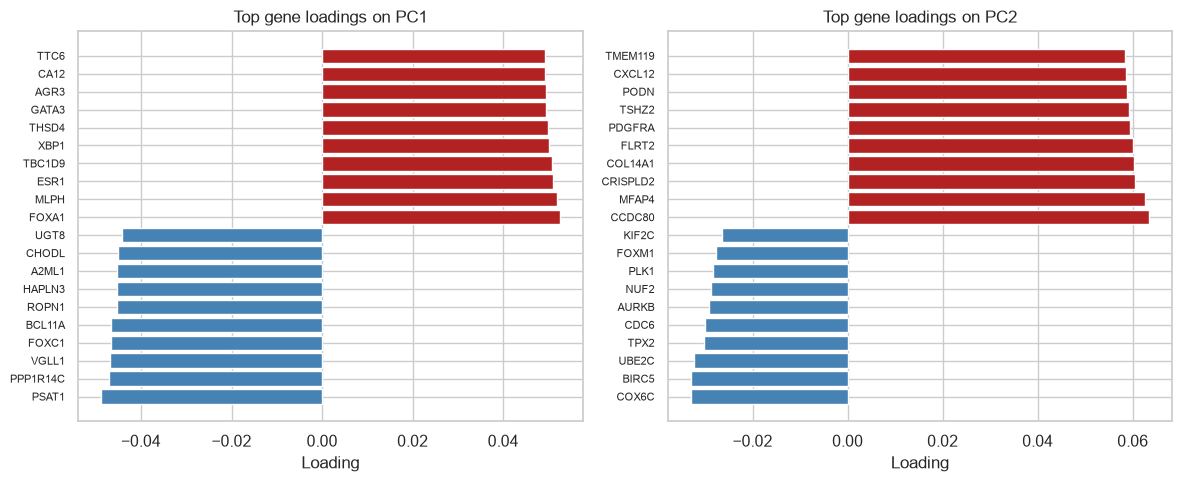

In [9]:
X = StandardScaler().fit_transform(logcpm.loc[hvg].T)          # samples x genes
pca = PCA(n_components=50, random_state=42).fit(X)
pcs = pca.transform(X)
evr = pca.explained_variance_ratio_
print(f"PC1 {evr[0]:.1%}, PC2 {evr[1]:.1%}, first 10 PCs {evr[:10].sum():.1%}, first 50 PCs {evr.sum():.1%}")
pc_df = pd.DataFrame(pcs[:, :10], columns=[f"PC{i}" for i in range(1, 11)])
pc_df[["subtype", "plate", "tss"]] = meta[["subtype", "plate", "tss"]].values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].bar(range(1, 21), evr[:20] * 100, color="steelblue", label="individual")
axes[0].plot(range(1, 21), np.cumsum(evr[:20]) * 100, "o-", color="firebrick", label="cumulative")
axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="% variance explained"); axes[0].legend()
for ax, (a, b) in zip(axes[1:], [("PC1", "PC2"), ("PC1", "PC3")]):
    sns.scatterplot(data=pc_df, x=a, y=b, hue="subtype", hue_order=SUB_ORDER, palette=PALETTE, s=14, alpha=0.8, ax=ax)
    ax.set(title=f"PCA: {a} vs {b}", xlabel=f"{a} ({evr[int(a[2:])-1]:.1%})", ylabel=f"{b} ({evr[int(b[2:])-1]:.1%})")
plt.tight_layout(); plt.savefig(FIG / "04_pca.png", dpi=200); plt.show()

# genes driving PC1 and PC2
load = pd.DataFrame(pca.components_[:2].T, index=hvg, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    top = pd.concat([load[pc].nsmallest(10), load[pc].nlargest(10)])
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "firebrick", "steelblue"))
    ax.set(title=f"Top gene loadings on {pc}", xlabel="Loading"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_pca_loadings.png", dpi=200); plt.show()

# UMAP

c:\Users\srika\Downloads\TCGA_BRCA_project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


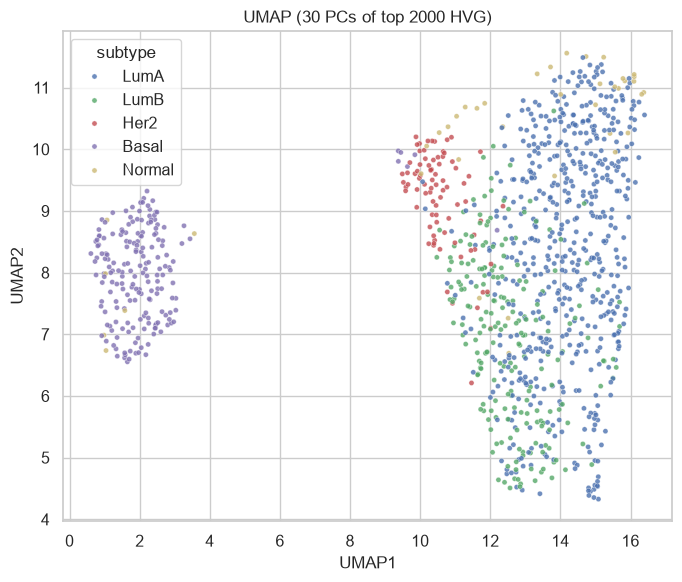

In [10]:
emb = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=42).fit_transform(pcs[:, :30])
pc_df["UMAP1"], pc_df["UMAP2"] = emb[:, 0], emb[:, 1]
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=pc_df, x="UMAP1", y="UMAP2", hue="subtype", hue_order=SUB_ORDER, palette=PALETTE, s=14, alpha=0.8, ax=ax)
ax.set(title="UMAP (30 PCs of top 2000 HVG)")
plt.tight_layout(); plt.savefig(FIG / "04_umap.png", dpi=200); plt.show()

# batch-effect check, then save the PCs for Step 5

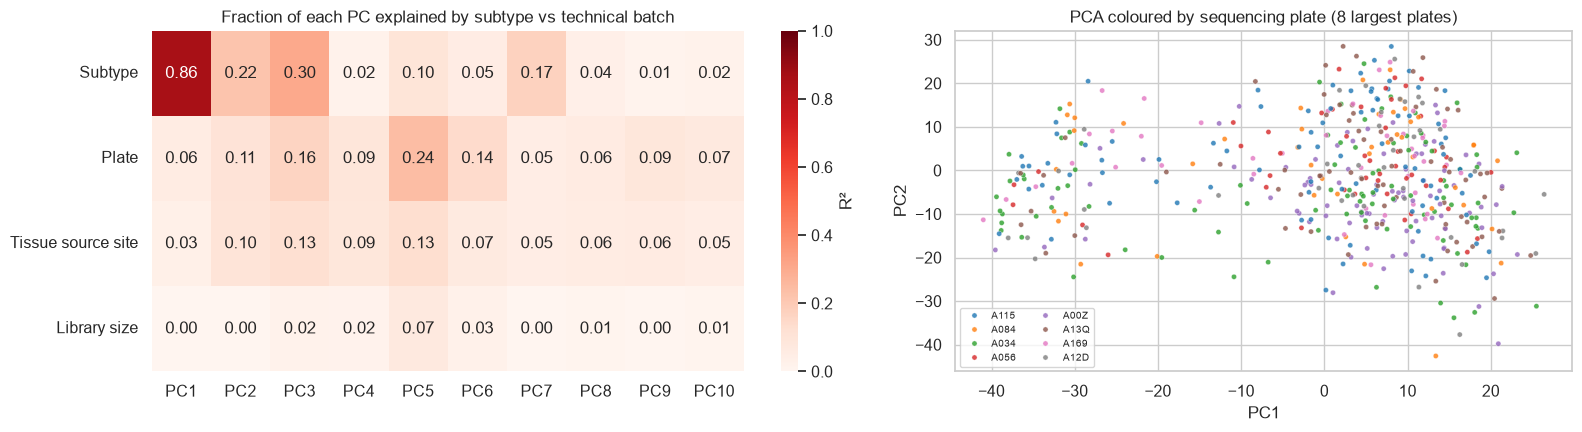

                      PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8    PC9   PC10
Subtype             0.864  0.222  0.305  0.022  0.099  0.053  0.175  0.038  0.012  0.022
Plate               0.056  0.108  0.164  0.091  0.244  0.143  0.048  0.061  0.089  0.072
Tissue source site  0.034  0.103  0.128  0.088  0.132  0.069  0.049  0.057  0.061  0.047
Library size        0.001  0.001  0.020  0.016  0.072  0.027  0.001  0.009  0.001  0.009


In [11]:
def r2(pc, group):       # eta-squared: share of a PC's variance explained by a grouping
    df = pd.DataFrame({"y": pc, "g": group})
    ss_between = df.groupby("g")["y"].apply(lambda v: len(v) * (v.mean() - df["y"].mean()) ** 2).sum()
    return ss_between / ((df["y"] - df["y"].mean()) ** 2).sum()

batch = pd.DataFrame({f"PC{i}": {
    "Subtype": r2(pc_df[f"PC{i}"], pc_df["subtype"]),
    "Plate": r2(pc_df[f"PC{i}"], pc_df["plate"]),
    "Tissue source site": r2(pc_df[f"PC{i}"], pc_df["tss"]),
    "Library size": np.corrcoef(pc_df[f"PC{i}"], meta["library_size_M"])[0, 1] ** 2,
} for i in range(1, 11)})
batch.to_csv(TAB / "04_pc_variance_explained_by_covariates.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(batch, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "R²"})
axes[0].set_title("Fraction of each PC explained by subtype vs technical batch")
top_plates = meta["plate"].value_counts().index[:8]
d = pc_df[pc_df["plate"].isin(top_plates)]
sns.scatterplot(data=d, x="PC1", y="PC2", hue="plate", s=14, alpha=0.8, ax=axes[1], palette="tab10")
axes[1].set(title="PCA coloured by sequencing plate (8 largest plates)"); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "04_batch_check.png", dpi=200); plt.show()
print(batch.round(3).to_string())

pd.DataFrame(pcs, columns=[f"PC{i}" for i in range(1, 51)], index=meta["sample_id"]).to_csv(PROC / "pca_top2000hvg.csv")
pd.Series(hvg, name="gene").to_csv(PROC / "hvg_top2000.csv", index=False)